# Photoreceptor segmentation using [napari](https://napari.org/) and [cellpose](https://cellpose-napari.readthedocs.io/en/latest/index.html)

### Basic usage:
```python
viewer = napari.Viewer()
nbscreenshot(viewer)
viewer.close()
```

example notebooks [here](https://github.com/sofroniewn/napari-training-course/blob/master/lessons/)

In [2]:
# !mamba install -c conda-forge devbio-napari --yes
# !jupyter labextension list
# !mamba install -c conda-forge cellpose-napari --yes
# from cellpose import models

ModuleNotFoundError: No module named 'cellpose'

In [2]:
# image analysis
import napari
from magicgui import magicgui
from enum import Enum
import cellpose_napari
import cellpose
from cellpose import models
from tifffile import imread
import napari_nikon_nd2
from skimage.io import imread
from magicgui import magicgui
# python basics and plotting
import numpy as np
import pandas as pd
import math
from scipy import ndimage
from scipy.stats import kruskal
from scipy.stats import zscore
from scipy.stats import sem
import scikit_posthocs
import scipy.spatial
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as font_manager
import svgutils
from svgutils.compose import *
# system interaction
import os.path
import time, sys, warnings, re
from tqdm.notebook import tqdm, trange
import importlib
import ipywidgets
from IPython.display import display
# lab brews
from plotParams import *
from lloyd import *


def getFileList(dirData,gene,fileNameMatch,addDetails=''):
   fileList = sorted([f for f in os.listdir(dirData) if not f.startswith('.')]) # get all the files in the data directory (excluding system files) and sort them alphabatically
   fileList = ([f for f in fileList if gene in f]) # select files that match the gene of interest
   fileList = ([f for f in fileList if any([s in f for s in fileNameMatch])]) # only keep relevant files
   if (addDetails=='path'):
      fileList = (['# filePath = \'' + f for f in fileList]) # add text before each file
      fileList = list(map(lambda st: str.replace(st, '.nd2', '\'; gene = \'' + gene + '\'; '), fileList)) #remove file extension (.nd2) and add text after each file
   elif (addDetails=='list'):
      fileList = (['\'' + f for f in fileList]) # add text before each file
      fileList = list(map(lambda st: str.replace(st, '.nd2', '\','), fileList)) #remove file extension (.nd2) and add text after each file
   else:
      fileList = list(map(lambda st: str.replace(st, '.nd2', ''), fileList)) #remove file extension (.nd2) and add text after each file
   return fileList


pBGMenu = ipywidgets.Dropdown(options=['Light', 'Dark'],value='Dark',disabled=False, layout=ipywidgets.Layout(width='20%', height='40px'))
pBGLabel = ipywidgets.widgets.Label('Select plotting style', layout=ipywidgets.Layout(width='20%', height='30px'))
pBG = ipywidgets.widgets.VBox([pBGLabel,pBGMenu])
pBG

In [3]:
applyPlotStyle(pBGMenu.value)
viewer = napari.Viewer()

Plotting style is Dark


In [13]:
viewer = napari.Viewer()

In [12]:
        viewer.close()

***
# Index <a id='Index'></a>
***
- [define directories](#dirDef)
- [Extraction of z planes for analysis](#zExtract)
- [Segmentation with cellpose](#cellSeg)
- [Manual correction of segmentation](#manualCuration)
- [Create thumbnails _WIP_](#thumbnails)
- [Quantification](#quantification)

***
## Define directories<a id='dirDefdirDef'>∮</a>
***
[Back to Index](#Index)

In [8]:
# define where all the imaging data is stored
dirData = 'Z:/AxR/20250818_tbx2ahetinx_m2G_tdT/'
# define where all the analysis files should be stored
# subdirectories for each gene and transgenic lines need to be manually made first
dirAnalysis = "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"

# Z:\Analysis\20250829_tbx2ahetinx_s2Cm2G_Counts_Sideviews\s2Cm2G\Denoised\20250829_5d_tbx2ahetinx_s2C_m2G_L13_003_Denoised

# # define where all the imaging data is stored
# dirData = 'D:/Imaging/0250202_2bhetinx_s2C_m2G/'
# # define where all the analysis files should be stored
# # subdirectories for each gene and transgenic lines need to be manually made first
# dirAnalysis = 'D:/Analysis/20250202_Tbx2bhetinx_m2Gs2C/m2Gs2C/'

In [9]:
gene = '' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
# gene = 'lhx1a' # usually 'wt' or gene of interest (e.g. 'tbx2a', 'lhx1a')
fileNameMatch = ['004','007'] # characters in filenames that define zoom-in files

# get a list with all the relevant files
print(*getFileList(dirData,gene,fileNameMatch,addDetails='path'), sep = "\n") #display the file list for copy and paste below

# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_004'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_004_Denoised'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_007'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L13_004'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L13_004_Denoised'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_004'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_004_Denoised'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_007'; gene = ''; 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_007_Denoised'; gene = ''; 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_004 _Denoised'; gene = ''; 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_004'; gene = ''; 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_007'; gene = ''; 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_004'; gene = ''; 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_007'; gene = ''; 
# filePath = '220250818_5

***
## Extract layers from z-stacks<a id='zExtract'>∮</a>
> Open z-stack &rarr; Pick limits in z for Maximum-Intensity Projection (_MIP_) &rarr; save MIPs &rarr; Ensure image was located in central retina
***
[Back to Index](#Index)

In [12]:
# clear viewer if needed
viewer.layers.select_all()
viewer.layers.remove_selected()

In [61]:
# clear viewer before any loading
viewer.layers.select_all()
viewer.layers.remove_selected()

# open files one by one (by commenting and uncommenting each one)

#5 dpf - Dorsal zoom in [00X, 00X] 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_002'; gene = ''; #cellcounting zoom in :( OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_006'; gene = ''; #CELLCOUNTING ZOOM IN - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_002'; gene = '';  #CELLCOUNTING ZOOM IN - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_006'; gene = '';  #CELLCOUNTING ZOOM IN - OMIT
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_003_Denoised'; gene = ''; zlims = [5,7];
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_007'; gene = ''; zlims = [0,4];
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L13_003 _Denoised'; gene = ''; zlims = [1,5];
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_003_Denoised'; gene = '';zlims = [13,16];
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_007_Denoised'; gene = ''; zlims = [9,11];

# Ventral Cones [003, 007] - comeback for misexpression in ventral retina
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_003'; gene = '';  #CELLCOUNTING ZOOM IN ventral to optic nerve - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_007'; gene = '';  #CELLCOUNTING ZOOM IN  ventral to optic nerve - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_003'; gene = ''; #CELLCOUNTING ZOOM IN  ventral to optic nerve - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_007'; gene = ''; #CELLCOUNTING ZOOM IN  ventral to optic nerve - OMIT



# SZ Cones [004, 008] 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L09_004'; gene = ''; zlims = [10,12]; #correct for orientation 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L09_008_Denoised'; gene = ''; zlims = [27,31]; #correct for orientation
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_004 _Denoised'; gene = '';zlims = [3,5];  #correct for orientation
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_008_Denoised'; gene = ''; #too curved - OMIT 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_004'; gene = ''; zlims = [23,25];
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_008'; gene = ''; zlims = [19,21]; #correct for orientation
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_004_Denoised'; gene = ''; zlims = [0,2]; #BEAUTIFUL! 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_008_Denoised'; gene = ''; zlims = [3,5]; #GORGEOUS
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L13_004_Denoised'; gene = ''; zlims = [4,7]; #TIPS LOOK SMOOSHED
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_008_Denoised'; gene = ''; zlims = [5,7]; #GORGEOUS

# 21 d Retinas 


# layerNames = ['R', 'U','PNA', 'N']
# layerNames = ['M', 'L', 'PNA', 'N']
layerNames = ['M', 'L', 'N']
# layerNames = ['N', 'U']

# create subdirectory for analysis output
dirOut = dirAnalysis + gene + '/' + filePath + '/'
if (os.path.isdir(dirOut)==False):
   os.mkdir(dirOut)
   print('Created output directory')

print('Canvas cleared. Loading data...\n\n')

# load whole stack to figure out best z-planes for cellpose
viewer.open((dirData+filePath + '.nd2'), plugin='napari-nikon-nd2')
viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
if len(viewer.layers)==2: #no DAPI
   nChannels = 2
   viewer.layers[0].colormap = 'cyan'
   viewer.layers[0].name = layerNames[0]
   viewer.layers[1].colormap = 'magenta'
   viewer.layers[1].name = layerNames[1]
elif len(viewer.layers)==3: #DAPI
   nChannels = 3
   viewer.layers[0].colormap = 'cyan'
   viewer.layers[0].name = 'N'
   viewer.layers[0].opacity = 0.99
   viewer.layers[1].colormap = 'green'
   viewer.layers[1].name = layerNames[0]
   viewer.layers[2].colormap = 'magenta'
   viewer.layers[2].name = layerNames[1]
   layerNames.append('N')
elif len(viewer.layers)==4: #DAPI
   nChannels = 4
   viewer.layers[0].colormap = 'gray'
   viewer.layers[0].name = 'N'
   viewer.layers[0].opacity = 0.99
   viewer.layers[1].colormap = 'green'
   viewer.layers[1].name = layerNames[0]
   viewer.layers[2].colormap = 'magenta'
   viewer.layers[2].name = layerNames[1]
   viewer.layers[3].colormap = 'bop orange'
   viewer.layers[3].name = layerNames[2]
   layerNames.append('N')

print('Images loaded!')

Created output directory
Canvas cleared. Loading data...


Images loaded!


In [62]:
# make mips (and remove any previous ones) by defining the z-limits to use
zlims = [4,7];
if len(viewer.layers)>nChannels:
    for l in viewer.layers[nChannels:]:
      viewer.layers.remove(l)

for l in viewer.layers[0:nChannels]:
    l.visible = False
#     viewer.layers.remove(l.name + '_mip')
    viewer.add_image(l.data[zlims[0]:zlims[1]].max(axis=0), blending='additive', colormap = l.colormap, name = l.name + "_mip")

In [63]:
# SAVE in folder for batch cellpose analysis (when mips look good)
for name in layerNames:
   l = viewer.layers[name + '_mip']; l.save(dirOut + l.name + '.tiff')
print('MIP layers saved for ' + filePath)

MIP layers saved for 220250817_5d_m2G_tdT_2ahetinx_L13_004_Denoised


### Establish landmarks in whole-eye MIP
- Use eyeMarks layer to mark:
    - [ ] Landmark #1: Center of FOV (where zoom in is centered)
    - [ ] Landmark #2: Center of Optic Nerve Head 
    - [ ] Landmark #3: Dorsal edge of eye
    - [ ] Landmark #4: Ventral edge of eye
    - [ ] Landmark #5: Temporal edge of eye (strike zone side)
    - [ ] Landmark #6: Nasal edge of eye
- Decide if stack should be excluded (and stop analysis here and make note in csv summary file)

In [106]:
nMIP = len(layerNames)
for name in layerNames:
   lName = name + "_mip"
   viewer.layers[lName].scale = [1.5/8,1.5/8];
   viewer.layers[lName].translate = [0,+(512-1024*1.5/(8*2))]

# Load whole-eye MIP to establish landmarks
print('Loading eye mip...')
if str.endswith(filePath,'002'):
    mipPath = filePath[:-1] + '1_mip';
elif str.endswith(filePath,'004'):
    mipPath = filePath[:-1] + '3_mip';
elif str.endswith(filePath,'b'):
    mipPath = filePath[:-1] + 'a_mip';
elif str.endswith(filePath,'d'):
    mipPath = filePath[:-1] + 'c_mip';
viewer.open((dirData+mipPath + '.nd2'), plugin='napari-nikon-nd2', blending='additive')

viewer.layers.remove(viewer.layers[len(viewer.layers)-1]) # remove transmitted detector image
viewer.layers.select_next();
eyeChannels = 0
if len(viewer.layers)==2+nMIP+nChannels: # no DAPI, GFP and RFP
   eyeChannels = 2
   viewer.layers[nMIP+nChannels].colormap = 'green'
   viewer.layers[nMIP+nChannels].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+1].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+1].name = 'eyeRed'
elif len(viewer.layers)==3+nMIP+nChannels: # leave DIC
   eyeChannels = 3
   viewer.layers[nMIP+nChannels+0].colormap = 'green'
   viewer.layers[nMIP+nChannels+0].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+1].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+1].name = 'eyeRed'
   viewer.layers[nMIP+nChannels+2].colormap = 'gray'
   viewer.layers[nMIP+nChannels+2].name = 'eyeBlue'
   viewer.layers[nMIP+nChannels+2].opacity = 0.33
elif len(viewer.layers)==4+nMIP+nChannels: #DIC + DAPI
   eyeChannels = 4
   viewer.layers[nMIP+nChannels+0].colormap = 'gray'
   viewer.layers[nMIP+nChannels+0].name = 'eyeBlue'
   viewer.layers[nMIP+nChannels+1].colormap = 'green'
   viewer.layers[nMIP+nChannels+1].name = 'eyeGreen'
   viewer.layers[nMIP+nChannels+2].colormap = 'magenta'
   viewer.layers[nMIP+nChannels+2].name = 'eyeRed'
   viewer.layers[nMIP+nChannels+3].colormap = 'bop orange'
   viewer.layers[nMIP+nChannels+3].name = 'eyePNA'
   viewer.layers[nMIP+nChannels+3].opacity = 0.33
print(eyeChannels)
print('Loaded: ' + filePath)
eyeMarks = viewer.add_points(size=20, name = 'eyeMarks', symbol='cross', face_color='#ffffff80')
viewer.layers.select_next();

# Save eye landmarks
eyeMarksButton = ipywidgets.Button(description='Save eyeMarks', layout=ipywidgets.Layout(width='200px', height='100px'))
out = ipywidgets.Output()
def eyeMClick(_):
   with out:
      l = viewer.layers['eyeMarks']; l.save(dirOut + l.name + '.csv');
      print('eyeMarks layers saved for ' + filePath)
   # clear viewer
   viewer.layers.select_all()
   viewer.layers.remove_selected()
   eyeMarksButton.disabled = True # to prevent double clicking warnings. All sales are final!

eyeMarksButton.on_click(eyeMClick)

print('Make 6 landmark points then click button to save')

ipywidgets.VBox([eyeMarksButton,out])

Loading eye mip...


FileNotFoundError: [Errno 2] No such file or directory: 'Z:\\AxR\\20250911_tbx2aNalou_s1C_xOG_Sideview\\20250911_5d_nalou_s1C_xOG_PNA_L10_004_Denoisec_mip.nd2'

### [Go back and run next one &uarr;](#zExtract)

***
## Quantification: GFP inside S cones<a id='quantification'>∮</a>
***
[Back to Index](#Index)

Plan (loosely based on Mander's coefficient):
1. Erode S cone segmentation to focus on center of cells
2. Divide GFP fluorescence into millies as a way to normalize data between images into 0 - 1000 range
3. Calculate for each cone what normalized average fluorescence corresponds too.

Questions:
1. How much erosion?
2. Do I have to exclude S cones to do GFP percentile calculation? &rarr; this would assume that GFP outside L cones is unchanged, which could be tested|plotted directly.
3. Also check if RFP distributions are unchanged?

In [26]:
erodeV = 10; #12;

# analysis directory
dAnalysis = "Z:/Analysis/20250829_tbx2ahetinx_s2Cm2G/s2Cm2G/"

# open file

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = [
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L01_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L03_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L04_002',
# '20250829_5dpf_tbx2ahetinx_s2C_m2G_L05_002', #curved -OMIT? 
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L06_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L06_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L07_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L08_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L08_006', 
# '20250829_5dpf_tbx2ahetinx_s2C_m2G_L09_002', #curved
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L09_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L10_006',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L11_002',
'20250829_5dpf_tbx2ahetinx_s2C_m2G_L12_002',
# '20250829_5d_tbx2ahetinx_s2C_m2G_L13_002', #curved zoom in
'20250829_5d_tbx2ahetinx_s2C_m2G_L14_002',
'20250829_5d_tbx2ahetinx_s2C_m2G_L15_002'
         ]
for fPath in wt_fPaths:
    GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
    for l in viewer.layers:
        viewer.layers.remove(l)
#QUANTIFIED GFP IN THE SAMPLES WOOHOO 10/20/2025    
    
# # tbx2a
# gene = 'tbx2a';
# tbx2a_fPaths = [
#                ]
# for fPath in tbx2a_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

# # tbx2b
# gene = 'tbx2b';
# tbx2b_fPaths = [
#                ]

# for fPath in tbx2b_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

print('Finished analysis')

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5dpf_tbx2ahetinx_s2C_m2G_L01_006(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5dpf_tbx2ahetinx_s2C_m2G_L02_006(2ahetinx)



... (24 outputs left out)

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in S cones of 20250829_5d_tbx2ahetinx_s2C_m2G_L15_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Finished analysis


In [13]:
erodeV = 10; #12;

# analysis directory
dAnalysis = "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"

# open file

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = [ '220250818_5d_2ahetinx_tdT_m2G_L01_002',
'220250818_5d_2ahetinx_tdT_m2G_L02_002',
'220250818_5d_2ahetinx_tdT_m2G_L03_002',
'220250818_5d_2ahetinx_tdT_m2G_L04_002',
 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
'220250818_5d_2ahetinx_tdT_m2G_L05_004',
'220250818_5d_2ahetinx_tdT_m2G_L06_002',
'220250818_5d_2ahetinx_tdT_m2G_L07_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_004',
'220250818_5d_2ahetinx_tdT_m2G_L09_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_006',
'220250818_5d_2ahetinx_tdT_m2G_L010_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_006',
#'220250817_5d_m2G_tdT_2ahetinx_L12_002',
'220250817_5d_m2G_tdT_2ahetinx_L12_006',
'220250817_5d_m2G_tdT_2ahetinx_L13_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
         ]
for fPath in wt_fPaths:
    GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
    for l in viewer.layers:
        viewer.layers.remove(l)
    
# # tbx2a
# gene = 'tbx2a';
# tbx2a_fPaths = ["20201009_5dpf_Rh22G_trb2T_CRtbx2a_i07b",
# #                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i07b",  # is this supposed to be d????
#                 # #### fPath = "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i08b", #very curved stack. would require oblique cut
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i08d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i09b",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i09d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i10b", #done; this could be example
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i10d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i11b", #done; very clean L-cone seg
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i11d",
#                 "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i12b",
#                 #### fPath = "20201009_5dpf_Rh22G_trb2T_CRtbx2a_i12d", # this in lens up
#                ]
# for fPath in tbx2a_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

# # tbx2b
# gene = 'tbx2b';
# tbx2b_fPaths = ["20201030_5dpf_Rh22G_trb2T_CRtbx2b_i07b",
#                 "20201030_5dpf_Rh22G_trb2T_CRtbx2b_i07d",
#                  "20201030_5dpf_Rh22G_trb2T_CRtbx2b_i08b",
#                 "20201030_5dpf_Rh22G_trb2T_CRtbx2b_i08d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L102b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L102d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L104b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L104d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L105b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L105d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L106b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L107b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L108b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L108d",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L109b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L110b",
#                 "20210716_5dpf_m2G_t2T_tbx2b_L111b",
#                ]

# for fPath in tbx2b_fPaths:
#     GFPanalyzer(viewer,dAnalysis,gene,fPath, erosionValue=erodeV)
#     for l in viewer.layers:
#         viewer.layers.remove(l)

print('Finished analysis')


C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250818_5d_2ahetinx_tdT_m2G_L01_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250818_5d_2ahetinx_tdT_m2G_L02_002(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250818_5d_2ahetinx_tdT_m2G_L03_002(2ahetinx)



... (30 outputs left out)

C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Quantifying GFP in L cones of 220250817_5d_m2G_tdT_2ahetinx_L14_006(2ahetinx)



C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(
C:\Users\Carin\mambaforge\envs\cellCounting\lib\site-packages\napari\components\viewer_model.py:977: UserWarning: The "builtins" plugin name is deprecated and will not work in a future version. Please use "napari" instead.
  warnings.warn(


Finished analysis


### collect all results

GFP threshold is 0.215
# cells of bright GFP cells: wt=4.451990190530088, tbx2a=3.8421599169262723, tbx2b=2.3376623376623376


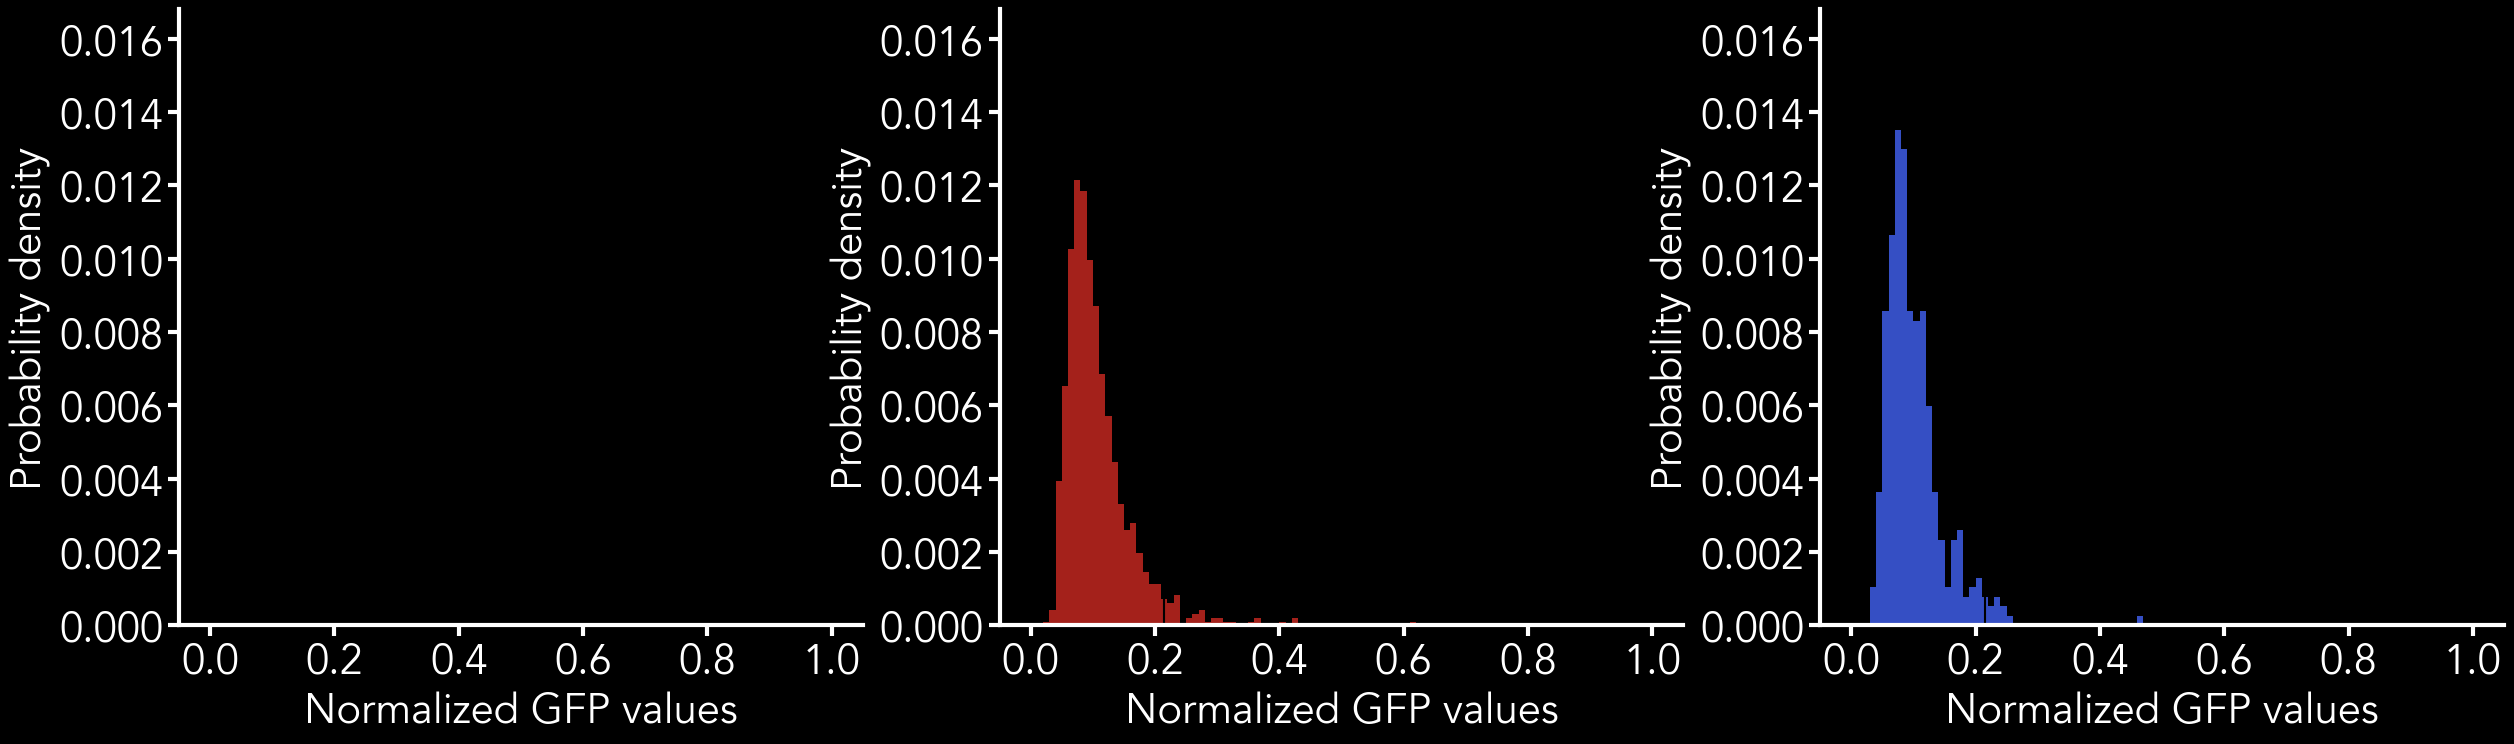

In [17]:
### After establishing threshold based on all data, count number of cells exceeding threshold for each eye# collect all results

# analysis directory
dAnalysis = "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"

#OpenFile

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L01_002',
'220250818_5d_2ahetinx_tdT_m2G_L02_002',
'220250818_5d_2ahetinx_tdT_m2G_L03_002',
 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
'220250818_5d_2ahetinx_tdT_m2G_L05_004',
'220250818_5d_2ahetinx_tdT_m2G_L06_002',
'220250818_5d_2ahetinx_tdT_m2G_L07_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_004',
'220250818_5d_2ahetinx_tdT_m2G_L010_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_006',
#'220250817_5d_m2G_tdT_2ahetinx_L12_002',
'220250817_5d_m2G_tdT_2ahetinx_L12_006',
'220250817_5d_m2G_tdT_2ahetinx_L13_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
         ]
# tbx2a
gene = '2ahetinx';
tbx2a_fPaths = [
'220250818_5d_2ahetinx_tdT_m2G_L04_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_006'
               ]
# tbx2b
gene = '2ahetinx';
tbx2b_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L01_002',

               ]
                
                
rName = 'lGtile'

wtResults = []
i=1;
for fPath in wt_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    wtResults.append(results[rName])
    i=i+1;

aResults = []
i=1;
for fPath in tbx2a_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    aResults.append(results[rName])
    i=i+1;

bResults = []
i=1;
for fPath in tbx2b_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
    bResults.append(results[rName])
    i=i+1;


# combine across images
wtResults = np.concatenate(wtResults).ravel()
aResults = np.concatenate(aResults).ravel()
bResults = np.concatenate(bResults).ravel()

# plot histogram
pdfV = True
# wtH, wtB = np.histogram(wtResults, bins = 50, density=pdfV)
# aH, aB = np.histogram(aResults, bins = 50, density=pdfV)
# bH, bB = np.histogram(bResults, bins = 50, density=pdfV)

# plot histogram but first calculate a fixed bin number for all genotypes
# allBins = np.histogram_bin_edges(np.concatenate([wtResults,aResults,bResults]).ravel(),bins='fd');
allBins = np.arange(0,1010,10);
allBinsC = (allBins[:-1] + allBins[1:]) / 2 # Centers
wtH, wtB = np.histogram(wtResults, bins = allBins, density=pdfV)
aH, aB = np.histogram(aResults, bins = allBins, density=pdfV)
bH, bB = np.histogram(bResults, bins = allBins, density=pdfV)

# # this can be used for cumulative distribution then normalized
# wtH = np.cumsum(wtH)/np.max(np.cumsum(wtH));
# aH = np.cumsum(aH)/np.max(np.cumsum(aH));
# bH = np.cumsum(bH)/np.max(np.cumsum(bH));

wt95CI = np.min(allBinsC[(np.cumsum(wtH))>.095])/1000;
wGBright = np.sum(wtH[allBinsC>wt95CI*1000]);
aGBright = np.sum(aH[allBinsC>wt95CI*1000]);
bGBright = np.sum(bH[allBinsC>wt95CI*1000]);

print('GFP threshold is {0}'.format(wt95CI))


baseColor='#000000'
# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, (axH1,axH2,axH3) = plt.subplots(nrows=1, ncols=3, figsize=(30, 8))
axH1.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH3.stairs(wtH,wtB/1000, fill=True, color = baseColor, alpha = 1.0)
axH2.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = 0.8)
axH3.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = 0.8)


axH1.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)
axH2.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)
axH3.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)


# axH.set_title('Distribution of GFP inside L cones')
for axH in (axH1,axH2,axH3):
    formatFigureMain(fH, axH, _)
    axH.set_xlabel('Normalized GFP values')
    if pdfV:
        axH.set_ylabel('Probability density')
    else:
        axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))

In [ ]:

# fH, (axH1,axH2,axH3) = plt.subplots(nrows=3, ncols=1, figsize=(10, 20))
fH, axH = plt.subplots(nrows=1, ncols=1, figsize=(9, 6))


# plot histogram
pdfV = True
# wtH, wtB = np.histogram(wtResults, bins = 50, density=pdfV)
# aH, aB = np.histogram(aResults, bins = 50, density=pdfV)
# bH, bB = np.histogram(bResults, bins = 50, density=pdfV)

# plot histogram but first calculate a fixed bin number for all genotypes
# allBins = np.histogram_bin_edges(np.concatenate([wtResults,aResults,bResults]).ravel(),bins='fd');
allBins = np.arange(0,1010,10);
allBinsC = (allBins[:-1] + allBins[1:]) / 2 # Centers
wtH, wtB = np.histogram(wtResults, bins = allBins, density=pdfV)
aH, aB = np.histogram(aResults, bins = allBins, density=pdfV)
bH, bB = np.histogram(bResults, bins = allBins, density=pdfV)

# # this can be used for cumulative distribution then normalized
# wtH = np.cumsum(wtH)/np.max(np.cumsum(wtH));
# aH = np.cumsum(aH)/np.max(np.cumsum(aH));
# bH = np.cumsum(bH)/np.max(np.cumsum(bH));

wt95CI = np.min(allBinsC[(np.cumsum(wtH))>.095])/1000;
wGBright = np.sum(wtH[allBinsC>wt95CI*1000]);
aGBright = np.sum(aH[allBinsC>wt95CI*1000]);
bGBright = np.sum(bH[allBinsC>wt95CI*1000]);


axH.stairs(wtH,wtB/1000, fill=True, color = 'k', alpha = .5)
axH.stairs(aH,aB/1000, fill=True, color = zfC['lws1'], alpha = .5)
axH.stairs(bH,bB/1000, fill=True, color = zfC['sws2'], alpha = .5)


axH.plot([wt95CI,wt95CI],[0,0.016],color=baseColor)

formatFigureMain(fH, axH, _)
# axH.set_title('Distribution of GFP inside L cones')
axH.set_xlabel('Normalized GFP values')
if pdfV:
    axH.set_ylabel('Probability density')
else:
    axH.set_ylabel('Counts')
## normalized
# axH.stairs(wtH/np.max(wtH),wtB, fill=True, color = 'k', alpha = 0.5)
# axH.stairs(aH/np.max(aH),aB, fill=True, color = 'r', alpha = 0.5)
# axH.stairs(bH/np.max(bH),bB, fill=True, color = 'b', alpha = 0.5)

# dPath = '/Users/angueyraaristjm/Documents/LiLab/Manuscripts/2021_zfConeRNAseq/resources/'
dPath = '/Users/angueyraaristjm/Documents/LiLab/Conferences/2021_RCS/resources/'
# plt.savefig(dPath + "CRtbx2F0_LM_hist.svg", transparent=True, format="svg")

print('# cells of bright GFP cells: wt={0}, tbx2a={1}, tbx2b={2}'.format(wGBright*1000,aGBright*1000,bGBright*1000))

### After establishing threshold based on all data, count number of cells exceeding threshold for each eye

Threshold (5%) is 0.215


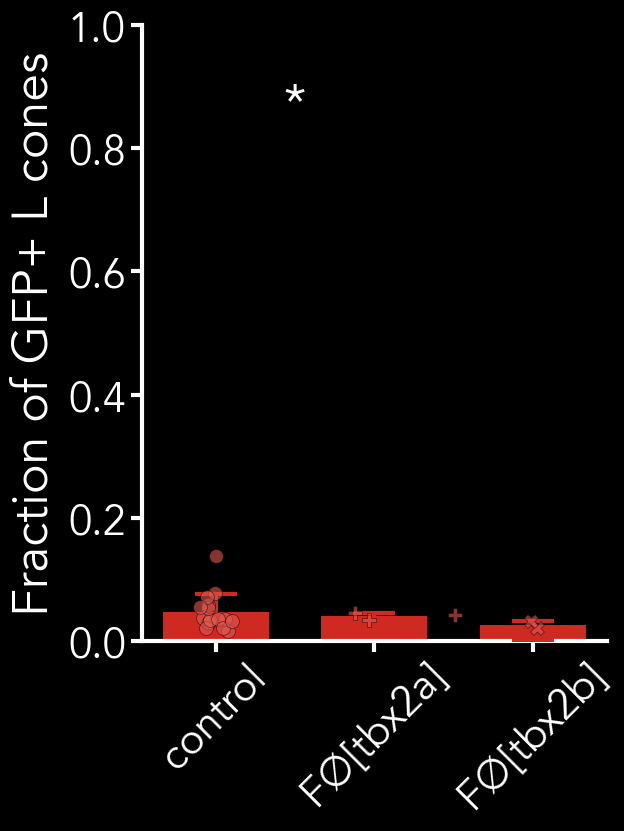

In [19]:
# collect all results

# analysis directory
dAnalysis =  "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"
# open file

# uninjected
### 20201009: imaged 3dpf and 5dpf larvae. Analyzing 5 dpf for paper
gene = '2ahetinx'
wt_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L01_002',
'220250818_5d_2ahetinx_tdT_m2G_L02_002',
'220250818_5d_2ahetinx_tdT_m2G_L03_002',
 '220250818_5d_2ahetinx_tdT_m2G_L05_002',
'220250818_5d_2ahetinx_tdT_m2G_L05_004',
'220250818_5d_2ahetinx_tdT_m2G_L06_002',
'220250818_5d_2ahetinx_tdT_m2G_L07_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_002',
'220250818_5d_2ahetinx_tdT_m2G_L08_004',
'220250818_5d_2ahetinx_tdT_m2G_L010_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_002',
'220250818_5d_2ahetinx_tdT_m2G_L011_006',
#'220250817_5d_m2G_tdT_2ahetinx_L12_002',
'220250817_5d_m2G_tdT_2ahetinx_L12_006',
'220250817_5d_m2G_tdT_2ahetinx_L13_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
         ]
# tbx2a
gene = '2ahetinx';
tbx2a_fPaths = ['220250818_5d_2ahetinx_tdT_m2G_L04_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_002',
'220250818_5d_2ahetinx_tdT_m2G_L09_006'
               ]
# tbx2b
gene = 'tbx2b';
tbx2b_fPaths = ['220250817_5d_m2G_tdT_2ahetinx_L14_002',
'220250817_5d_m2G_tdT_2ahetinx_L14_006'
               ]
                
rName = 'lGtile'

wtResults = []
i=1;
for fPath in wt_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     wtResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    wtResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

    
aResults = []
i=1;
for fPath in tbx2a_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     aResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    aResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

bResults = []
i=1;
for fPath in tbx2b_fPaths:
    gene = '2ahetinx'
    dOut = dAnalysis + gene + '/' + fPath + '/'
    results = np.load(dOut + 'quantificationGFP.npz')
#     bResults.append(np.count_nonzero(results['lGtile']>wt95CI*1000)) #this is for absolute counts
    bResults.append(np.divide(np.count_nonzero(results['lGtile']>wt95CI*1000),len(results['lGtile']))) #this is for fraction
    i=i+1;

# geneList = ['2ahetinx','tbx2a','tbx2b']

geneList = ['2ahetinx']

plotname = ''
fH, axH = plt.subplots(figsize= [6,8])

barW = np.size(geneList)+2; # bar width
barD = np.size(geneList)+1; # bar distance whitin 1 photoreceptor subtype
barP = -np.size(geneList)+1; # position in x-axis
barStep = 0.9; # distance between photoreceptor groups
barPos = []; #array to save bar positions


jitter = estimateJitter(wtResults)/400
pH = plt.bar([barStep+1/barD], np.mean(wtResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+1/barD], np.mean(wtResults), yerr = [[0.025],[np.std(wtResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(wtResults))*[barStep+1/barD]+jitter, wtResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['wt'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+1/barD))



jitter = estimateJitter(aResults)/400
pH = plt.bar([barStep+2/barD], np.mean(aResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+2/barD], np.mean(aResults), yerr = [[0.025],[np.std(aResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(aResults))*[barStep+2/barD]+jitter, aResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2a'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+2/barD))

jitter = estimateJitter(bResults)/400
pH = plt.bar([barStep+3/barD], np.mean(bResults), width=1/barW, color=zfC['lws1']);
pH = plt.errorbar([barStep+3/barD], np.mean(bResults), yerr = [[0.025],[np.std(bResults)]], ecolor=lighten_color(zfC['lws1'],1), elinewidth=3, capsize=15, capthick=3, zorder=7)
pH = plt.scatter(np.ones(len(bResults))*[barStep+3/barD]+jitter, bResults, color=lighten_color(zfC['lws1'],.75), zorder=8, marker = zfGm['tbx2b'], s=100, edgecolor='#000000', linewidth=0.5, alpha = .6);
barPos = np.append(barPos,(barStep+3/barD))

fontProps = formatFigureMain(fH, axH, pH)

# axH.set_ylabel('GFP+ L cones per 64 x 64 $\mu$m$^2$', fontproperties=formatFigureMain(fH, axH, pH))
# axH.set_ylim([0,180]);
# stath = 170

axH.set_ylabel('Fraction of GFP+ L cones', fontproperties=fontProps)
axH.set_ylim([0,1]);
stath = 0.85

geneList = ['control','F$\emptyset$[tbx2a]','F$\emptyset$[tbx2b]']

axH.xaxis.set_tick_params(rotation=45)
axH.set_xticks(np.sort(barPos));
axH.set_xticklabels(geneList);

hH = plt.hlines(stath, barPos[0], barPos[1], colors='#000000',linewidth=4)
plt.text((barPos[0]+barPos[1])/2, stath, '*', font_properties=fontProps, fontsize=36, ha='center')# plt.savefig(savePath + "Counts_tbx2_RU.svg", transparent=True, format="svg")


dPath = '/Users/angueyraaristjm/OneDrive - National Institutes of Health/zf/Manuscripts/2021_zfConeRNAseq/resources/'
# dPath = '/Users/angueyraaristjm/Documents/LiLab/Presentations/revealjs/resources/20211008_UCLA/'
# plt.savefig(dPath + "CRtbx2F0_GFPLcones.svg", transparent=True, format="svg")

print('Threshold (5%) is {0}'.format(wt95CI))

### Load segmentaion file (TIFF) and extract data to save as  NUMPY Array 

In [77]:

# Import libraries
import numpy as np
from skimage import measure, io
from skimage.measure import regionprops

dirData = 'Z:/AxR/20250818_tbx2ahetinx_m2G_tdT/'
# define where all the analysis files should be stored
# subdirectories for each gene and transgenic lines need to be manually made first
dirAnalysis = "Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/"

# DEFINE List of layer names
layerNames = ['M', 'L', 'N']


# clear viewer before any loading
viewer.layers.select_all()
viewer.layers.remove_selected()

## Load Segmentation files: 

#5 dpf - Dorsal zoom in [00X, 00X] 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_002'; gene = ''; #cellcounting zoom in :( OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_006'; gene = ''; #CELLCOUNTING ZOOM IN - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_002'; gene = '';  #CELLCOUNTING ZOOM IN - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_006'; gene = '';  #CELLCOUNTING ZOOM IN - OMIT
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_003_Denoised'; gene = ''; zlims = [5,7]; #normal galvo orientation
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_007'; gene = ''; zlims = [0,4]; #normal galvo orientation
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L13_003 _Denoised'; gene = ''; zlims = [1,5]; #normal galvo orientation
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_003_Denoised'; gene = '';zlims = [13,16]; #normal galvo orientation
filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_007_Denoised'; gene = ''; zlims = [9,11]; #check orientation (pixel dimensions)

# Ventral Cones [003, 007] - comeback for misexpression in ventral retina
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_003'; gene = '';  #CELLCOUNTING ZOOM IN ventral to optic nerve - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_007'; gene = '';  #CELLCOUNTING ZOOM IN  ventral to optic nerve - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_003'; gene = ''; #CELLCOUNTING ZOOM IN  ventral to optic nerve - OMIT
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_007'; gene = ''; #CELLCOUNTING ZOOM IN  ventral to optic nerve - OMIT



# SZ Cones [004, 008] 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L09_004'; gene = ''; zlims = [10,12]; #correct for orientation 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L09_008_Denoised'; gene = ''; zlims = [27,31]; #correct for orientation
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_004 _Denoised'; gene = '';zlims = [3,5];  #correct for orientation- #pixels 2048X2048 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L010_008_Denoised'; gene = ''; #too curved - OMIT 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_004'; gene = ''; zlims = [23,25]; #pixels 2048X2048 
# filePath = '220250818_5d_2ahetinx_tdT_m2G_L011_008'; gene = ''; zlims = [19,21]; #correct for orientation
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_004_Denoised'; gene = ''; zlims = [0,2]; #BEAUTIFUL! 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L12_008_Denoised'; gene = ''; zlims = [3,5]; #GORGEOUS - issue with storing dimensions on one label 
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L13_004_Denoised'; gene = ''; zlims = [4,7]; #TIPS LOOK SMOOSHED - not strikezone (change region or omit)
# filePath = '220250817_5d_m2G_tdT_2ahetinx_L14_008_Denoised'; gene = ''; zlims = [5,7]; #GORGEOUS #saved in CSV



# load mips
mipO = 0.65
viewer.open(dirAnalysis + filePath + '/' + layerNames[0] + "_mip.tiff", plugin='napari', colormap = 'green', blending='additive', opacity=mipO);
viewer.open(dirAnalysis + filePath + '/' +  layerNames[1] + "_mip.tiff", plugin='napari', colormap = 'magenta', blending='additive', opacity=mipO);

print("Loaded mip")

# # Load Segmentation TIFF 
viewer.open(dirAnalysis + filePath + '/' + layerNames[0] + "_seg_curated.tif", plugin='napari', colormap = 'green', blending='additive', opacity=mipO);
viewer.open(dirAnalysis + filePath + '/' + layerNames[1] + "_seg_curated.tif", plugin='napari', colormap = 'magenta', blending='additive', opacity=mipO);


print("Loaded Segmentation TIFF")

dirOut = dirAnalysis + filePath + '/' 

# Code for turning to numpy array 

lname_0 = layerNames[0] + '_seg_curated'
lname_1 = layerNames[1] + '_seg_curated'

# Access the data from the Napari layer
layer0_data = viewer.layers[lname_0].data
layer1_data = viewer.layers[lname_1].data


# Save the data as a NumPy array with filenames reflecting the layer
np.save(dirOut + layerNames[0] + '_seg_curated.npy', layer0_data)
print(f'Saved {layerNames[0]}_seg_curated as NumPy array.')

np.save(dirOut + layerNames[1] + '_seg_curated.npy', layer1_data)
print(f'Saved {layerNames[1]}_seg_curated as NumPy array.')


Loaded mip
Loaded Segmentation TIFF
Saved M_seg_curated as NumPy array.
Saved L_seg_curated as NumPy array.


### Calculate Cell Length 

In [52]:
layer_data.astype(np.int32)

array([[160, 169, 153, ..., 191, 165, 201],
       [177, 154, 160, ..., 214, 253, 236],
       [159, 141, 157, ..., 172, 162, 250],
       ...,
       [176, 150, 148, ..., 152, 145, 188],
       [155, 139, 175, ..., 181, 144, 174],
       [148, 152, 170, ..., 197, 181, 162]])

In [78]:
## Calculate cell length and width using Scikit-Image 


# # Calculate pixel spacing (dimensions from ND2 files)
# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 40 / 1024  # microns per pixel|

# # Calculate cell lengths using regionprops - RODS ONLY 
# for i, layer_data in enumerate([layer0_data]):
#     props = measure.regionprops(layer_data)
#     print(f"Cell lengths for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Assuming measurements are along the major axis in the XY plane
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # or y_pixel_spacing if needed
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns")
        
        
        
# Calculate pixel spacing (dimensions from ND2 files)
x_pixel_spacing = 80 / 2048  # microns per pixel
y_pixel_spacing = 40 / 1024  # microns per pixel

# x_pixel_spacing = 102.05 / 512  # microns per pixel
# y_pixel_spacing = 51.02 / 256  # microns per pixel

# x_pixel_spacing = 83 / 1024  # microns per pixel
# y_pixel_spacing = 37 / 486  # microns per pixel

# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 80 / 2048  # microns per pixel

# Calculate cell lengths using regionprops 
for i, layer_data in enumerate([layer0_data, layer1_data]):
    props = measure.regionprops(layer_data.astype(np.int32))
    print(f"Cell lengths for {layerNames[i]} (in microns):")
    for prop in props:
        # Assuming measurements are along the major axis in the XY plane
        length_in_microns = prop.major_axis_length * x_pixel_spacing  # or y_pixel_spacing if needed
        print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns")


Cell lengths for M (in microns):
 - Cell ID 1: Length = 16.87 microns
 - Cell ID 2: Length = 16.70 microns
 - Cell ID 3: Length = 15.74 microns
 - Cell ID 4: Length = 17.00 microns
 - Cell ID 5: Length = 17.55 microns
 - Cell ID 6: Length = 14.13 microns
 - Cell ID 7: Length = 17.90 microns
 - Cell ID 8: Length = 14.13 microns
Cell lengths for L (in microns):
 - Cell ID 1: Length = 17.76 microns
 - Cell ID 2: Length = 17.14 microns
 - Cell ID 3: Length = 17.39 microns
 - Cell ID 4: Length = 17.47 microns
 - Cell ID 5: Length = 14.19 microns
 - Cell ID 6: Length = 15.55 microns
 - Cell ID 7: Length = 15.97 microns
 - Cell ID 8: Length = 17.38 microns


### Calculate Cell Width

In [80]:
# Calculate pixel spacing - RODS ONLY 
# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 40 / 1024  # microns per pixel

# # Calculate cell widths (minor axis length) using regionprops
# for i, layer_data in enumerate([layer0_data]):
#     props = measure.regionprops(layer_data)
#     print(f"Cell dimensions for {layerNames[i]} (in microns):")
#     for prop in props:
#         # Calculate length and width in microns
#         length_in_microns = prop.major_axis_length * x_pixel_spacing  # Assuming major axis aligns with X
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing   # Assuming minor axis aligns with Y
#         print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns, Width = {width_in_microns:.2f} microns")



# Calculate pixel spacing - UV AND RODS 
x_pixel_spacing = 80 / 2048  # microns per pixel
y_pixel_spacing = 40 / 1024  # microns per pixel

# x_pixel_spacing = 102 / 512  # microns per pixel
# y_pixel_spacing = 51 / 256  # microns per pixel

# x_pixel_spacing = 83 / 1024  # microns per pixel
# y_pixel_spacing = 37 / 486  # microns per pixel

# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 80 / 2048  # microns per pixel

# Calculate cell widths (minor axis length) using regionprops
for i, layer_data in enumerate([layer0_data, layer1_data]):
    props = measure.regionprops(layer_data)
    print(f"Cell dimensions for {layerNames[i]} (in microns):")
    for prop in props:
        # Calculate length and width in microns
        length_in_microns = prop.major_axis_length * x_pixel_spacing  # Assuming major axis aligns with X
        width_in_microns = prop.minor_axis_length * y_pixel_spacing   # Assuming minor axis aligns with Y
        print(f" - Cell ID {prop.label}: Length = {length_in_microns:.2f} microns, Width = {width_in_microns:.2f} microns")

Cell dimensions for M (in microns):
 - Cell ID 1: Length = 16.87 microns, Width = 3.92 microns
 - Cell ID 2: Length = 16.70 microns, Width = 4.18 microns
 - Cell ID 3: Length = 15.74 microns, Width = 3.49 microns
 - Cell ID 4: Length = 17.00 microns, Width = 4.02 microns
 - Cell ID 5: Length = 17.55 microns, Width = 3.58 microns
 - Cell ID 6: Length = 14.13 microns, Width = 4.00 microns
 - Cell ID 7: Length = 17.90 microns, Width = 4.33 microns
 - Cell ID 8: Length = 14.13 microns, Width = 4.61 microns
Cell dimensions for L (in microns):
 - Cell ID 1: Length = 17.76 microns, Width = 4.20 microns
 - Cell ID 2: Length = 17.14 microns, Width = 4.71 microns
 - Cell ID 3: Length = 17.39 microns, Width = 3.80 microns
 - Cell ID 4: Length = 17.47 microns, Width = 4.62 microns
 - Cell ID 5: Length = 14.19 microns, Width = 4.22 microns
 - Cell ID 6: Length = 15.55 microns, Width = 4.53 microns
 - Cell ID 7: Length = 15.97 microns, Width = 4.84 microns
 - Cell ID 8: Length = 17.38 microns, Width

In [81]:
import numpy as np
from skimage import io, measure
import pandas as pd

# Define pixel spacing
x_pixel_spacing = 80 / 2048  # microns per pixel
y_pixel_spacing = 40 / 1024  # microns per pixel

# x_pixel_spacing = 102 / 512  # microns per pixel
# y_pixel_spacing = 51 / 256  # microns per pixel

# x_pixel_spacing = 83 / 1024  # microns per pixel
# y_pixel_spacing = 37 / 486  # microns per pixel

# x_pixel_spacing = 80 / 2048  # microns per pixel
# y_pixel_spacing = 80 / 2048  # microns per pixel

# Prepare a list to store data
data = []


# # Calculate cell dimensions and store them [RODS ONLY]
# for i, layer_data in enumerate([layer0_data]):
#     props = measure.regionprops(layer_data)
#     layer_name = layerNames[i]
#     for prop in props:
#         length_in_microns = prop.major_axis_length * x_pixel_spacing
#         width_in_microns = prop.minor_axis_length * y_pixel_spacing
#         data.append({
#             'Layer': layer_name,
#             'Cell ID': prop.label,
#             'Length (microns)': length_in_microns,
#             'Width (microns)': width_in_microns
#         })

# Calculate cell dimensions and store them [UV AND RODS]
for i, layer_data in enumerate([layer0_data, layer1_data]):
    props = measure.regionprops(layer_data)
    layer_name = layerNames[i]
    for prop in props:
        length_in_microns = prop.major_axis_length * x_pixel_spacing
        width_in_microns = prop.minor_axis_length * y_pixel_spacing
        data.append({
            'Layer': layer_name,
            'Cell ID': prop.label,
            'Length (microns)': length_in_microns,
            'Width (microns)': width_in_microns
        })

# Convert to DataFrame
df = pd.DataFrame(data)

# Define the output file path
csv_file_path = dirOut + 'cell_dimensions.csv'

# Write to CSV
df.to_csv(csv_file_path, index=False)

print(f"Cell dimensions saved to {csv_file_path}")

Cell dimensions saved to Z:/Analysis/20250817_tbx2ahetinx_m2G_tdT/m2GtdT/220250817_5d_m2G_tdT_2ahetinx_L14_007_Denoised/cell_dimensions.csv
